<a href="https://colab.research.google.com/github/samadhan-ai4m/ccfraudxgboost/blob/main/ccfraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix
from xgboost import XGBClassifier

In [ ]:
data = pd.read_csv('/content/creditcard.csv')
print(data.shape)
print(data.head())
print(data.isnull().sum())

(284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V

In [ ]:
data["Class"].value_counts()

,count
Class,
0,284315
1,492


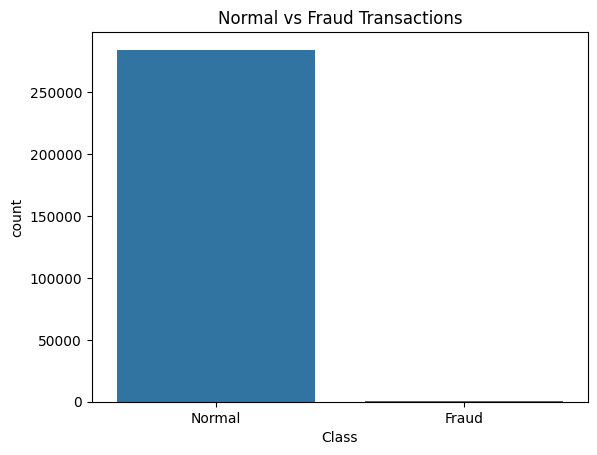

In [ ]:
sns.countplot(data=data, x="Class")
plt.title("Normal vs Fraud Transactions")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.show()

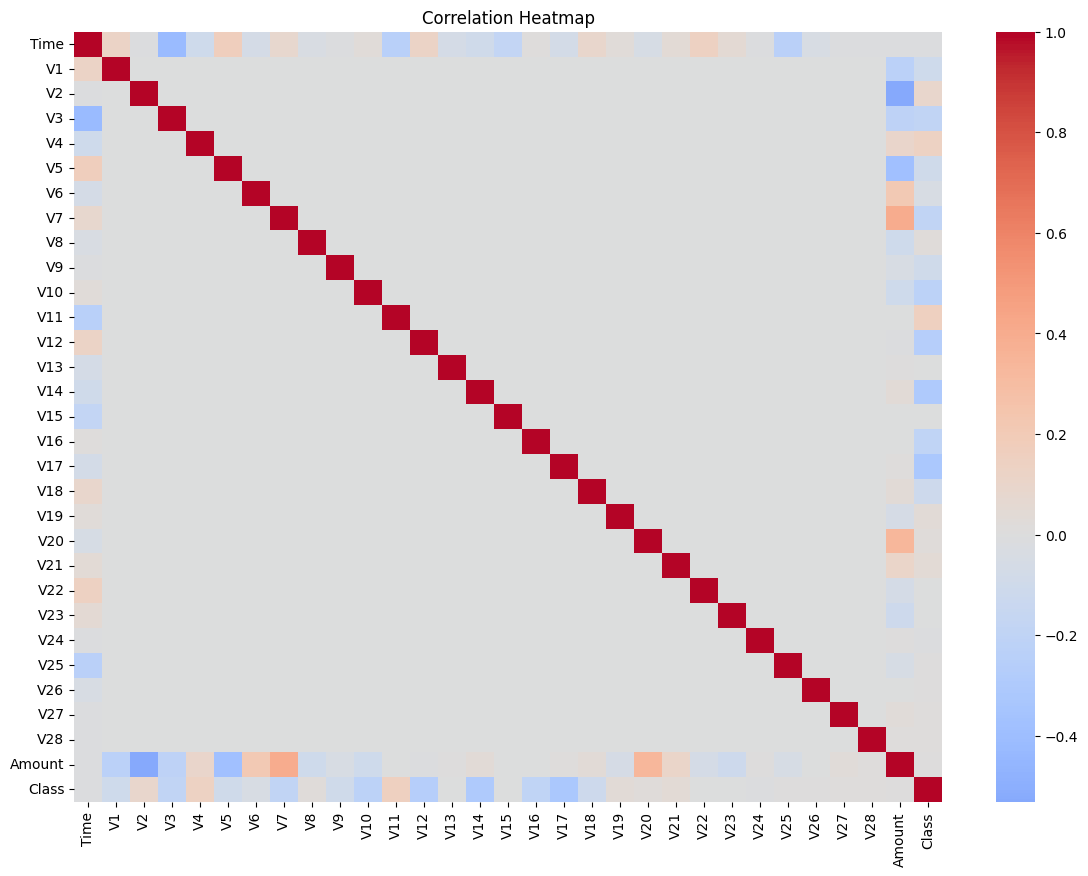

In [ ]:
plt.figure(figsize=(14, 10))

correlation = data.corr(numeric_only=True)

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0

)

plt.title("Correlation Heatmap")
plt.show()

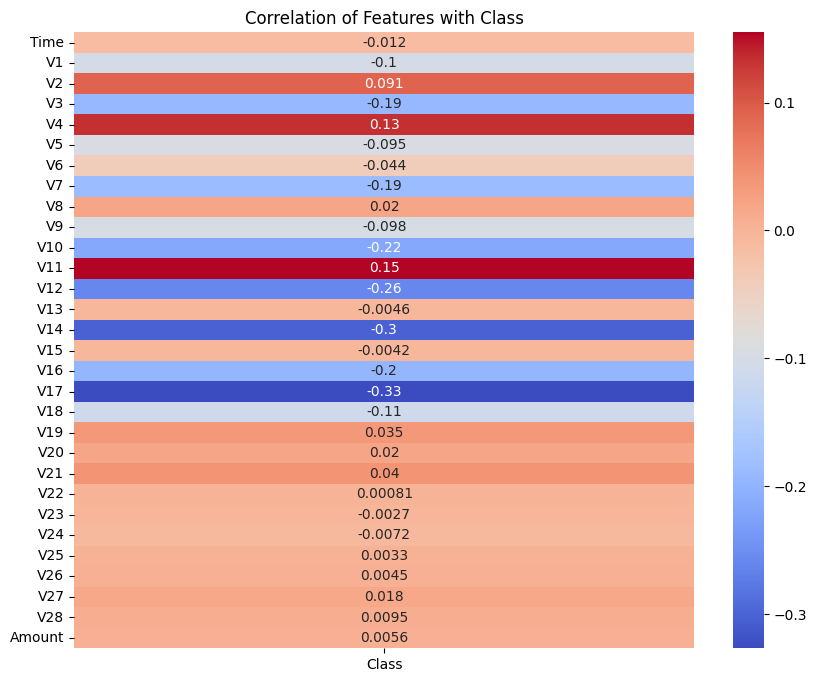

In [ ]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation[["Class"]].drop(index="Class"),
    annot=True,
    cmap="coolwarm",

)

plt.title("Correlation of Features with Class")
plt.show()

In [ ]:
X = data.drop(columns=["Class"])
y = data["Class"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
scale_pos_weight = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

model = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred
))

Confusion Matrix:
[[56829    35]
 [   12    86]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.71      0.88      0.79        98

    accuracy                           1.00     56962
   macro avg       0.86      0.94      0.89     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:
joblib.dump(model, "fraud_xgboost.joblib")

['fraud_xgboost.joblib']

In [ ]:
FEATURES = X.drop(columns=[], errors="ignore").columns.tolist()

joblib.dump(FEATURES, "features.joblib")

print("Features saved successfully!")
print(FEATURES)

Features saved successfully!
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [ ]:
model.save_model("fraud_xgboost.json")